# Exploración HSV masked RoCoLe

Este EDA mira solo la tabla HSV masked. Objetivo: ver si los dieciséis bins HSV enmascarados separan sanas de afectadas en train (calidad, univariados de pocos bins, clases y correlaciones) y decidir con honestidad si vale la pena un 04 con RGB/GLCM más HSV, solo HSV, o aparcar la familia.


## Rutas y semilla

Apuntamos al CSV hsv_hist_features_masked y a la carpeta de figuras. Semilla 42 por si hay muestreos visuales.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path


In [2]:
# Semilla fija para muestreos visuales reproducibles
seed = 42
repo_root = Path("../..").resolve()
features_path = repo_root / "data" / "featured" / "rocole" / "hsv_hist_features_masked.csv"
results_dir = repo_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("seed:", seed)
print("features_path:", features_path)
print("existe:", features_path.exists())
print("results_dir:", results_dir)
seed, features_path, results_dir


seed: 42
features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\hsv_hist_features_masked.csv
existe: True
results_dir: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results


(42,
 WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/data/featured/rocole/hsv_hist_features_masked.csv'),
 WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results'))

## Cargar tabla HSV

Cargamos la mesa HSV: identidad, dieciséis bins y error. Es la única fuente de este cuaderno.


In [3]:
hsv_leaves = pd.read_csv(features_path)

hsv_leaves.head()


,File,split,link_group,Binary.Label,Multiclass.Label,error,hsv_h_b0,hsv_h_b1,hsv_h_b2,hsv_h_b3,...,hsv_h_b6,hsv_h_b7,hsv_s_b0,hsv_s_b1,hsv_s_b2,hsv_s_b3,hsv_v_b0,hsv_v_b1,hsv_v_b2,hsv_v_b3
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.000180,0.011176,0.944385,0.044259,...,0.000000,0.000000,0.010138,0.429587,0.452823,0.107453,0.000353,0.305308,0.662189,0.032151
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.039306,0.355705,0.604945,0.000010,...,0.000002,0.000027,0.004484,0.442161,0.552731,0.000624,0.000522,0.015845,0.827815,0.155819
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.000208,0.127795,0.818221,0.053776,...,0.000000,0.000000,0.129314,0.303065,0.368171,0.199449,0.000242,0.031814,0.624172,0.343772
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.001579,0.313902,0.684165,0.000024,...,0.000036,0.000282,0.106949,0.791879,0.100388,0.000784,0.001639,0.012354,0.772775,0.213232
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.081139,0.852689,0.062831,0.000038,...,0.000016,0.003287,0.006619,0.695575,0.296780,0.001025,0.001270,0.030871,0.600927,0.366932


## Inspección de la tabla

Miramos cuántas filas y columnas hay, y las primeras filas, para confirmar que el inventario llegó entero.


In [4]:
# hsv_leaves

print("forma:", hsv_leaves.shape)
print("columnas:", list(hsv_leaves.columns))

hsv_leaves.head()


forma: (1481, 22)
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'hsv_h_b0', 'hsv_h_b1', 'hsv_h_b2', 'hsv_h_b3', 'hsv_h_b4', 'hsv_h_b5', 'hsv_h_b6', 'hsv_h_b7', 'hsv_s_b0', 'hsv_s_b1', 'hsv_s_b2', 'hsv_s_b3', 'hsv_v_b0', 'hsv_v_b1', 'hsv_v_b2', 'hsv_v_b3']


,File,split,link_group,Binary.Label,Multiclass.Label,error,hsv_h_b0,hsv_h_b1,hsv_h_b2,hsv_h_b3,...,hsv_h_b6,hsv_h_b7,hsv_s_b0,hsv_s_b1,hsv_s_b2,hsv_s_b3,hsv_v_b0,hsv_v_b1,hsv_v_b2,hsv_v_b3
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.000180,0.011176,0.944385,0.044259,...,0.000000,0.000000,0.010138,0.429587,0.452823,0.107453,0.000353,0.305308,0.662189,0.032151
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.039306,0.355705,0.604945,0.000010,...,0.000002,0.000027,0.004484,0.442161,0.552731,0.000624,0.000522,0.015845,0.827815,0.155819
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.000208,0.127795,0.818221,0.053776,...,0.000000,0.000000,0.129314,0.303065,0.368171,0.199449,0.000242,0.031814,0.624172,0.343772
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.001579,0.313902,0.684165,0.000024,...,0.000036,0.000282,0.106949,0.791879,0.100388,0.000784,0.001639,0.012354,0.772775,0.213232
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.081139,0.852689,0.062831,0.000038,...,0.000016,0.003287,0.006619,0.695575,0.296780,0.001025,0.001270,0.030871,0.600927,0.366932


## Calidad y errores

Contamos errores de máscara o lectura y cuántas filas tienen bins vacíos. La calidad condiciona cuánto podemos confiar en el solape.


In [5]:
error_series = hsv_leaves["error"].fillna("").astype(str).str.strip()
extraction_error_count = int((error_series != "").sum())
hsv_bin_guess = [
    c
    for c in hsv_leaves.columns
    if c.startswith("hsv_h_b") or c.startswith("hsv_s_b") or c.startswith("hsv_v_b")
]
null_counts_bins = (
    hsv_leaves[hsv_bin_guess].isna().sum() if hsv_bin_guess else pd.Series(dtype=int)
)
rows_with_null_bins = (
    int(hsv_leaves[hsv_bin_guess].isna().any(axis=1).sum()) if hsv_bin_guess else 0
)
quality_summary = {
    "n_rows": int(len(hsv_leaves)),
    "extraction_error_count": extraction_error_count,
    "rows_with_null_bins": rows_with_null_bins,
    "null_counts_bins": null_counts_bins.to_dict() if len(null_counts_bins) else {},
}

print("filas:", quality_summary["n_rows"])
print("filas con error de extracción:", quality_summary["extraction_error_count"])
print("filas con algún bin nulo:", quality_summary["rows_with_null_bins"])
print("nulos por bin:", quality_summary["null_counts_bins"])
quality_summary


filas: 1481
filas con error de extracción: 0
filas con algún bin nulo: 0
nulos por bin: {'hsv_h_b0': 0, 'hsv_h_b1': 0, 'hsv_h_b2': 0, 'hsv_h_b3': 0, 'hsv_h_b4': 0, 'hsv_h_b5': 0, 'hsv_h_b6': 0, 'hsv_h_b7': 0, 'hsv_s_b0': 0, 'hsv_s_b1': 0, 'hsv_s_b2': 0, 'hsv_s_b3': 0, 'hsv_v_b0': 0, 'hsv_v_b1': 0, 'hsv_v_b2': 0, 'hsv_v_b3': 0}


C:\Users\victo\AppData\Local\Temp\ipykernel_16148\2520184917.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  error_series = hsv_leaves["error"].fillna("").astype(str).str.strip()


{'n_rows': 1481,
 'extraction_error_count': 0,
 'rows_with_null_bins': 0,
 'null_counts_bins': {'hsv_h_b0': 0,
  'hsv_h_b1': 0,
  'hsv_h_b2': 0,
  'hsv_h_b3': 0,
  'hsv_h_b4': 0,
  'hsv_h_b5': 0,
  'hsv_h_b6': 0,
  'hsv_h_b7': 0,
  'hsv_s_b0': 0,
  'hsv_s_b1': 0,
  'hsv_s_b2': 0,
  'hsv_s_b3': 0,
  'hsv_v_b0': 0,
  'hsv_v_b1': 0,
  'hsv_v_b2': 0,
  'hsv_v_b3': 0}}

Separamos las dieciséis columnas de histograma del resto. Son las medidas; la etiqueta sigue en la misma fila. No codificamos la etiqueta todavía.


In [6]:
# hsv_leaves

hsv_feature_columns = [
    "hsv_h_b0",
    "hsv_h_b1",
    "hsv_h_b2",
    "hsv_h_b3",
    "hsv_h_b4",
    "hsv_h_b5",
    "hsv_h_b6",
    "hsv_h_b7",
    "hsv_s_b0",
    "hsv_s_b1",
    "hsv_s_b2",
    "hsv_s_b3",
    "hsv_v_b0",
    "hsv_v_b1",
    "hsv_v_b2",
    "hsv_v_b3",
]
missing_feature_columns = [c for c in hsv_feature_columns if c not in hsv_leaves.columns]

print("columnas HSV pedidas:", len(hsv_feature_columns))
print("faltan en la tabla:", missing_feature_columns)
hsv_feature_columns


columnas HSV pedidas: 16
faltan en la tabla: []


['hsv_h_b0',
 'hsv_h_b1',
 'hsv_h_b2',
 'hsv_h_b3',
 'hsv_h_b4',
 'hsv_h_b5',
 'hsv_h_b6',
 'hsv_h_b7',
 'hsv_s_b0',
 'hsv_s_b1',
 'hsv_s_b2',
 'hsv_s_b3',
 'hsv_v_b0',
 'hsv_v_b1',
 'hsv_v_b2',
 'hsv_v_b3']

Apartamos solo las hojas de aprender. Si hay error de extracción, las filtramos aquí. Clases, solapes y correlaciones se miran en train; el test no decide.


In [7]:
# hsv_leaves

error_mask = hsv_leaves["error"].fillna("").astype(str).str.strip() != ""
train_leaves = hsv_leaves.loc[
    (hsv_leaves["split"] == "train") & (~error_mask)
].copy()

print("train filas (sin error):", len(train_leaves))
print("excluidas por error en todo el CSV:", int(error_mask.sum()))
train_leaves.head()


train filas (sin error): 1037
excluidas por error en todo el CSV: 0


C:\Users\victo\AppData\Local\Temp\ipykernel_16148\3077728099.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  error_mask = hsv_leaves["error"].fillna("").astype(str).str.strip() != ""


,File,split,link_group,Binary.Label,Multiclass.Label,error,hsv_h_b0,hsv_h_b1,hsv_h_b2,hsv_h_b3,...,hsv_h_b6,hsv_h_b7,hsv_s_b0,hsv_s_b1,hsv_s_b2,hsv_s_b3,hsv_v_b0,hsv_v_b1,hsv_v_b2,hsv_v_b3
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.000180,0.011176,0.944385,0.044259,...,0.000000,0.000000,0.010138,0.429587,0.452823,0.107453,0.000353,0.305308,0.662189,0.032151
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.039306,0.355705,0.604945,0.000010,...,0.000002,0.000027,0.004484,0.442161,0.552731,0.000624,0.000522,0.015845,0.827815,0.155819
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.000208,0.127795,0.818221,0.053776,...,0.000000,0.000000,0.129314,0.303065,0.368171,0.199449,0.000242,0.031814,0.624172,0.343772
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.001579,0.313902,0.684165,0.000024,...,0.000036,0.000282,0.106949,0.791879,0.100388,0.000784,0.001639,0.012354,0.772775,0.213232
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.081139,0.852689,0.062831,0.000038,...,0.000016,0.003287,0.006619,0.695575,0.296780,0.001025,0.001270,0.030871,0.600927,0.366932


Elegimos pocos cajones representativos —dos de matiz, uno de saturación y uno de valor— para no ahogarnos en dieciséis gráficos. Todavía no dibujamos ni correlacionamos todo.


In [8]:
# hsv_feature_columns

# Dos de H, uno de S y uno de V: cobertura mínima sin saturar figuras
representative_bins = ["hsv_h_b0", "hsv_h_b3", "hsv_s_b1", "hsv_v_b2"]

print("representative_bins:", representative_bins)
representative_bins


representative_bins: ['hsv_h_b0', 'hsv_h_b3', 'hsv_s_b1', 'hsv_v_b2']


['hsv_h_b0', 'hsv_h_b3', 'hsv_s_b1', 'hsv_v_b2']

Miramos la distribución de esos pocos bins en train, sin cortar outliers ni elegir umbral. Figuras con prefijo rocole-hsv-masked-.


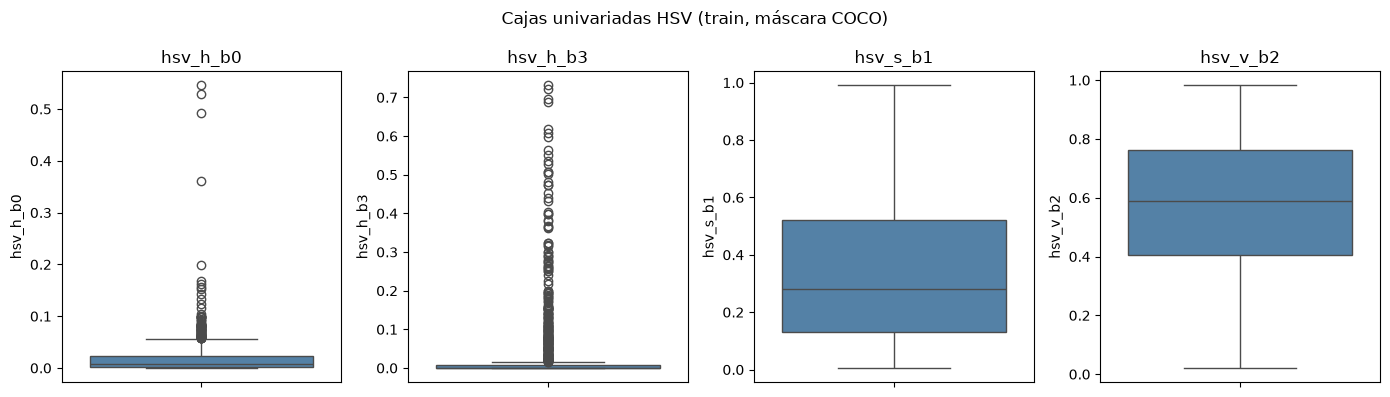

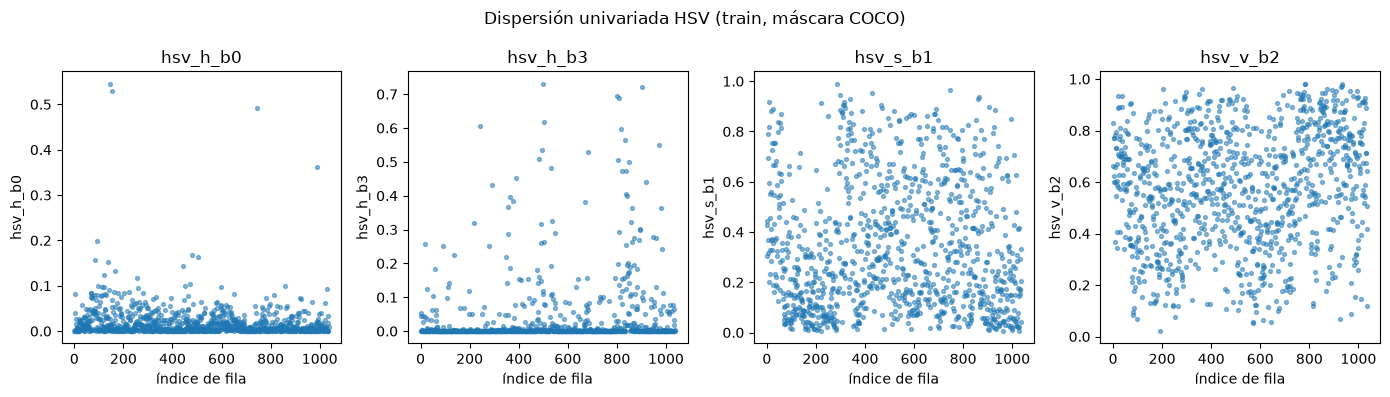

figuras guardadas:
  D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-hsv-masked-representative-boxplots.png
  D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-hsv-masked-representative-scatter.png


[WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-hsv-masked-representative-boxplots.png'),
 WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-hsv-masked-representative-scatter.png')]

In [9]:
fig, axes = plt.subplots(1, len(representative_bins), figsize=(14, 4))
for axis, column in zip(axes, representative_bins):
    sns.boxplot(y=train_leaves[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas univariadas HSV (train, máscara COCO)")
fig.tight_layout()
univariate_box_path = results_dir / "rocole-hsv-masked-representative-boxplots.png"
fig.savefig(univariate_box_path, dpi=120, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(representative_bins), figsize=(14, 4))
row_index = np.arange(len(train_leaves))
for axis, column in zip(axes, representative_bins):
    axis.scatter(row_index, train_leaves[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada HSV (train, máscara COCO)")
fig.tight_layout()
univariate_scatter_path = results_dir / "rocole-hsv-masked-representative-scatter.png"
fig.savefig(univariate_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

univariate_figures = [univariate_box_path, univariate_scatter_path]

print("figuras guardadas:")
for path in univariate_figures:
    print(" ", path)
univariate_figures


Comparamos esos mismos bins entre sanas y afectadas, solo en train, para ver si hay separación a ojo. No entrenamos ni miramos el test.


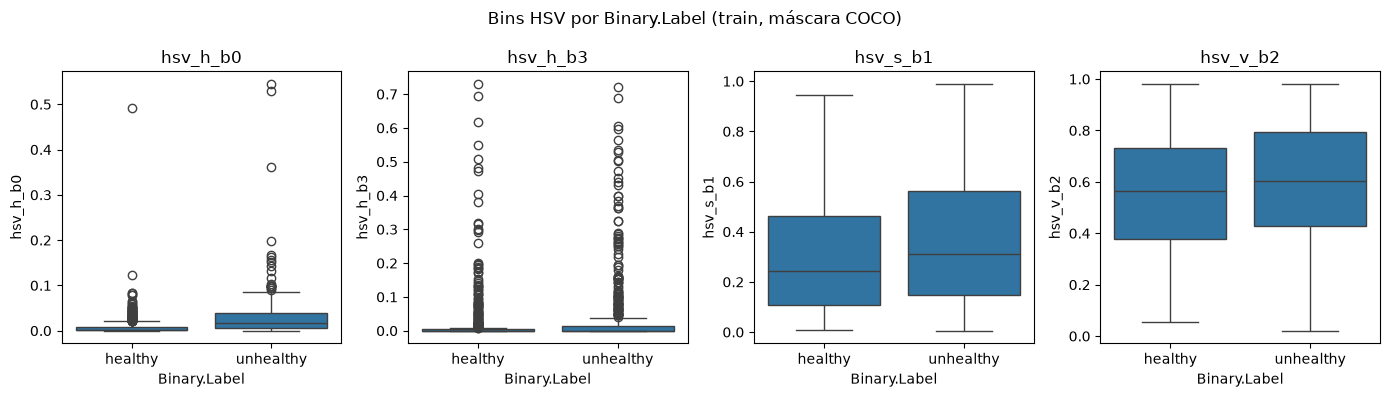

figura guardada: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-hsv-masked-representative-by-label-boxplots.png


[WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-hsv-masked-representative-by-label-boxplots.png')]

In [10]:
# train_leaves, representative_bins, results_dir

fig, axes = plt.subplots(1, len(representative_bins), figsize=(14, 4))
for axis, column in zip(axes, representative_bins):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("Bins HSV por Binary.Label (train, máscara COCO)")
fig.tight_layout()
class_compare_path = results_dir / "rocole-hsv-masked-representative-by-label-boxplots.png"
fig.savefig(class_compare_path, dpi=120, bbox_inches="tight")
plt.show()

class_compare_figures = [class_compare_path]

print("figura guardada:", class_compare_path)
class_compare_figures


Nos fijamos en el solape entre sanas y afectadas: si las cajas se montan casi del todo, la señal es débil aunque haya diferencia de medias. No pasamos a modelo ni usamos Multiclass.Label como color.


In [11]:
# train_leaves, representative_bins

overlap_rows = []
for column in representative_bins:
    for label_name, group in train_leaves.groupby("Binary.Label"):
        values = group[column].dropna()
        overlap_rows.append(
            {
                "bin": column,
                "Binary.Label": label_name,
                "n": int(len(values)),
                "q25": float(values.quantile(0.25)) if len(values) else np.nan,
                "median": float(values.median()) if len(values) else np.nan,
                "q75": float(values.quantile(0.75)) if len(values) else np.nan,
                "min": float(values.min()) if len(values) else np.nan,
                "max": float(values.max()) if len(values) else np.nan,
            }
        )
overlap_notes = pd.DataFrame(overlap_rows)

# Tras correr: anotar a ojo si el IQR sana/afectada se monta casi entero
print(overlap_notes.to_string(index=False))
overlap_notes


     bin Binary.Label   n      q25   median      q75      min      max
hsv_h_b0      healthy 530 0.000805 0.002581 0.008788 0.000000 0.492449
hsv_h_b0    unhealthy 507 0.005732 0.016977 0.038281 0.000071 0.545524
hsv_h_b3      healthy 530 0.000006 0.000232 0.003564 0.000000 0.730919
hsv_h_b3    unhealthy 507 0.000008 0.000350 0.014916 0.000000 0.722483
hsv_s_b1      healthy 530 0.108857 0.243378 0.463798 0.006522 0.946809
hsv_s_b1    unhealthy 507 0.148338 0.311114 0.562232 0.005561 0.990120
hsv_v_b2      healthy 530 0.377815 0.565515 0.732027 0.054045 0.981898
hsv_v_b2    unhealthy 507 0.427180 0.601561 0.793083 0.021026 0.979191


,bin,Binary.Label,n,q25,median,q75,min,max
0,hsv_h_b0,healthy,530,0.000805,0.002581,0.008788,0.000000,0.492449
1,hsv_h_b0,unhealthy,507,0.005732,0.016977,0.038281,0.000071,0.545524
2,hsv_h_b3,healthy,530,0.000006,0.000232,0.003564,0.000000,0.730919
3,hsv_h_b3,unhealthy,507,0.000008,0.000350,0.014916,0.000000,0.722483
4,hsv_s_b1,healthy,530,0.108857,0.243378,0.463798,0.006522,0.946809
5,hsv_s_b1,unhealthy,507,0.148338,0.311114,0.562232,0.005561,0.990120
6,hsv_v_b2,healthy,530,0.377815,0.565515,0.732027,0.054045,0.981898
7,hsv_v_b2,unhealthy,507,0.427180,0.601561,0.793083,0.021026,0.979191


Pasamos la etiqueta binaria a números (sana 0, afectada 1) solo para correlacionar, sin entrenar. Sin severidad ni el split de test.


In [12]:
# train_leaves

binary_label_code = train_leaves["Binary.Label"].map(
    {"healthy": 0, "unhealthy": 1}
)

print(binary_label_code.value_counts(dropna=False))
binary_label_code


Binary.Label
0    530
1    507
Name: count, dtype: int64


0       0
1       1
2       0
3       0
4       1
       ..
1475    0
1476    1
1477    0
1478    1
1479    1
Name: Binary.Label, Length: 1037, dtype: int64

Correlación de cada bin HSV con el código de etiqueta en train. Miramos magnitud y signo; no es ranking de predictoras definitivo. No ajustamos modelo ni elegimos columnas con acierto en test.


In [13]:
# train_leaves, hsv_feature_columns, binary_label_code

feature_label_correlation = train_leaves[hsv_feature_columns].corrwith(
    binary_label_code
).sort_values(key=lambda s: s.abs(), ascending=False)

print(feature_label_correlation)
feature_label_correlation


hsv_h_b0    0.259868
hsv_v_b3   -0.149766
hsv_h_b7    0.146678
hsv_h_b5    0.129040
hsv_s_b3   -0.112580
hsv_h_b2   -0.111091
hsv_s_b1    0.103469
hsv_h_b6    0.096270
hsv_h_b3    0.094592
hsv_v_b2    0.094012
hsv_h_b4    0.072745
hsv_s_b2    0.066368
hsv_h_b1    0.047500
hsv_s_b0   -0.040549
hsv_v_b1    0.018883
hsv_v_b0    0.009310
dtype: float64


hsv_h_b0    0.259868
hsv_v_b3   -0.149766
hsv_h_b7    0.146678
hsv_h_b5    0.129040
hsv_s_b3   -0.112580
hsv_h_b2   -0.111091
hsv_s_b1    0.103469
hsv_h_b6    0.096270
hsv_h_b3    0.094592
hsv_v_b2    0.094012
hsv_h_b4    0.072745
hsv_s_b2    0.066368
hsv_h_b1    0.047500
hsv_s_b0   -0.040549
hsv_v_b1    0.018883
hsv_v_b0    0.009310
dtype: float64

Con lo visto (calidad, solape, correlaciones) decidimos con honestidad: ¿sumar HSV a las siete RGB/GLCM masked, probar solo HSV, o aparcar? Un 04-hsv solo si hay señal clara. No entrenamos baseline en este cuaderno.


In [14]:
# quality_summary, overlap_notes, feature_label_correlation

# Evidencia del run (train, 1037 hojas, 0 errores):
# - mejor |corr| con etiqueta: hsv_h_b0 ≈ 0.26; hsv_v_b3 ≈ -0.15; hsv_h_b7 ≈ 0.15
# - solape sano/afectado sigue grande en cajas (IQR se montan)
# - señal moderada, comparable a homogeneidad GLCM masked; no basta sola
hsv_go_decision = "sumar_hsv_a_rgb_glcm"

print("hsv_go_decision:", hsv_go_decision)
print(
    "Motivo: matiz aporta señal moderada y probablemente complementaria "
    "a las 7 RGB/GLCM masked; aparcar sería prematuro; solo-HSV no tiene soporte."
)
hsv_go_decision


hsv_go_decision: sumar_hsv_a_rgb_glcm
Motivo: matiz aporta señal moderada y probablemente complementaria a las 7 RGB/GLCM masked; aparcar sería prematuro; solo-HSV no tiene soporte.


'sumar_hsv_a_rgb_glcm'

## Conclusiones

Inventario HSV masked: 1481 filas, 0 errores, 16 bins que suman 1 por canal.

En train, la mejor correlación con la etiqueta es hsv_h_b0 (cerca de 0.26). Hay señal, pero el solape sana/afectada sigue grande: no es un separador limpio por sí solo.

Decisión: sumar_hsv_a_rgb_glcm. Tiene sentido probar un baseline que una las 7 medidas RGB/GLCM masked con estos 16 bins, eligiendo en val. No abrir un baseline solo-HSV todavía.

Los cuadernos 01–04 publicados (full y masked RGB/GLCM) no se tocan; esto sigue siendo rama de desarrollo.
